# Session 5: File Handling and Exception Handling

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in ['attendance_raw.csv']:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-05_file_basics.py`

In [2]:
"""
Session 5 · Example 1: file access modes and file methods
---------------------------------------------------------
All files are created in a temporary folder that is deleted at the end,
so running the script leaves nothing behind.
Run:  python session-05_file_basics.py
"""
import os
import tempfile
from pathlib import Path

start = os.getcwd()                              # remember where we started
work = tempfile.mkdtemp()
os.chdir(work)                                   # work inside the temp folder

# 'w' write: creates the file, or EMPTIES it if it exists
with open("notes.txt", "w", encoding="utf-8") as f:   # 'with' closes the file automatically
    f.write("Line 1: Python files\n")
    f.writelines(["Line 2: modes r w a x\n", "Line 3: Urdu works too: کراچی\n"])
print("closed after with-block?", f.closed)

# 'r' read (the default): the whole file, one line, or all lines
with open("notes.txt", encoding="utf-8") as f:
    print("read():", repr(f.read(20)), "... first 20 characters")
    print("tell() after 20 chars ->", f.tell(), "bytes")
    f.seek(0)                                    # jump back to the start
    print("readline():", repr(f.readline()))
    print("readlines():", f.readlines())

# Iterate line by line: memory-friendly for huge files
with open("notes.txt", encoding="utf-8") as f:
    for number, line in enumerate(f, start=1):
        print(f"  {number}: {line.rstrip()}")

# 'a' append: adds to the end, never erases
with open("notes.txt", "a", encoding="utf-8") as f:
    print("Line 4: appended with print(file=f)", file=f)
print("line count now:", sum(1 for _ in open("notes.txt", encoding="utf-8")))

# 'x' exclusive create: fails if the file already exists (safe against overwriting)
try:
    open("notes.txt", "x")
except FileExistsError as e:
    print("mode 'x':", type(e).__name__, "-", e.strerror)

# 'r+' read and write without truncating
with open("notes.txt", "r+", encoding="utf-8") as f:
    f.write("LINE")                              # overwrites the first 4 characters
    f.seek(0)
    print("after r+:", f.readline().rstrip())

# Binary mode 'rb' / 'wb': bytes, not text (images, PDFs, pickles)
with open("pixel.bin", "wb") as f:
    f.write(bytes([255, 107, 26]))               # the RGB colour #FF6B1A
with open("pixel.bin", "rb") as f:
    data = f.read()
print("binary:", data, "->", list(data), "| size", os.path.getsize("pixel.bin"), "bytes")

# pathlib: the modern, object-oriented way to work with paths
p = Path("reports") / "2026" / "october.txt"
p.parent.mkdir(parents=True, exist_ok=True)
p.write_text("Total: 42\n", encoding="utf-8")
print("pathlib:", p, "| exists:", p.exists(), "| suffix:", p.suffix, "| stem:", p.stem,
      "| text:", p.read_text(encoding="utf-8").strip())
print("all .txt files:", sorted(str(x) for x in Path(".").rglob("*.txt")))

# Rename and delete
os.rename("notes.txt", "notes_old.txt")
os.remove("pixel.bin")
print("folder now:", sorted(os.listdir(".")))

import shutil
os.chdir(start); shutil.rmtree(work)             # go back, then delete the demo folder
print("cleaned up:", not os.path.exists(work))

closed after with-block? True
read(): 'Line 1: Python files' ... first 20 characters
tell() after 20 chars -> 20 bytes
readline(): 'Line 1: Python files\n'
readlines(): ['Line 2: modes r w a x\n', 'Line 3: Urdu works too: کراچی\n']
  1: Line 1: Python files
  2: Line 2: modes r w a x
  3: Line 3: Urdu works too: کراچی
line count now: 4
mode 'x': FileExistsError - File exists
after r+: LINE 1: Python files
binary: b'\xffk\x1a' -> [255, 107, 26] | size 3 bytes
pathlib: reports/2026/october.txt | exists: True | suffix: .txt | stem: october | text: Total: 42
all .txt files: ['notes.txt', 'reports/2026/october.txt']
folder now: ['notes_old.txt', 'reports']
cleaned up: True


## Example: `session-05_csv_json.py`

In [3]:
"""
Session 5 · Example 2: structured files - CSV and JSON
------------------------------------------------------
Run:  python session-05_csv_json.py
"""
import csv
import json
import os
import shutil
import tempfile

start, work = os.getcwd(), tempfile.mkdtemp()
os.chdir(work)                      # demo files go to a temporary folder

students = [
    {"roll": "AI-01", "name": "Ali Khan", "city": "Karachi", "marks": 78},
    {"roll": "AI-02", "name": "Sana Tariq", "city": "Lahore", "marks": 91},
    {"roll": "AI-03", "name": "Bilal, Jr.", "city": "Karachi", "marks": 64},   # comma inside a value!
]

# --- CSV: write with DictWriter (handles quoting of commas for you) ---
with open("students.csv", "w", newline="", encoding="utf-8") as f:   # newline="" avoids blank lines on Windows
    writer = csv.DictWriter(f, fieldnames=["roll", "name", "city", "marks"])
    writer.writeheader()
    writer.writerows(students)
print("raw CSV text:\n" + open("students.csv", encoding="utf-8").read())

# --- CSV: read rows as dicts. Every value comes back as TEXT ---
with open("students.csv", newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
print("first row:", rows[0])
print("type of marks:", type(rows[0]["marks"]).__name__, "-> convert before maths")
avg = sum(int(r["marks"]) for r in rows) / len(rows)
print(f"average marks: {avg:.2f}")

# csv.reader gives plain lists
with open("students.csv", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)
    karachi = [row[1] for row in reader if row[2] == "Karachi"]
print("header:", header, "| Karachi students:", karachi)

# --- JSON: nested data (dicts, lists, numbers, strings, bools, null) ---
config = {
    "course": "Diploma in AI",
    "term": 1,
    "modules": ["T-SQL", "MongoDB", "Statistics", "Python"],
    "lab": {"room": "B-204", "pcs": 30, "projector": True},
    "coordinator": None,
}
with open("config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)              # pretty-printed file

with open("config.json", encoding="utf-8") as f:
    loaded = json.load(f)
print("\nJSON round trip equal?", loaded == config)
print("lab room:", loaded["lab"]["room"], "| modules:", len(loaded["modules"]))

# dumps / loads work with strings (used for web APIs in Sessions 7-8)
text = json.dumps({"ok": True, "items": [1, 2]})
print("dumps ->", text, "| loads ->", json.loads(text))
print("Python None/True become JSON:", json.dumps([None, True, False]))
try:
    json.loads("{'single': 'quotes'}")            # not valid JSON
except json.JSONDecodeError as e:
    print("JSONDecodeError:", e.msg)

os.chdir(start); shutil.rmtree(work)   # tidy up

raw CSV text:
roll,name,city,marks
AI-01,Ali Khan,Karachi,78
AI-02,Sana Tariq,Lahore,91
AI-03,"Bilal, Jr.",Karachi,64

first row: {'roll': 'AI-01', 'name': 'Ali Khan', 'city': 'Karachi', 'marks': '78'}
type of marks: str -> convert before maths
average marks: 77.67
header: ['roll', 'name', 'city', 'marks'] | Karachi students: ['Ali Khan', 'Bilal, Jr.']

JSON round trip equal? True
lab room: B-204 | modules: 4
dumps -> {"ok": true, "items": [1, 2]} | loads -> {'ok': True, 'items': [1, 2]}
Python None/True become JSON: [null, true, false]
JSONDecodeError: Expecting property name enclosed in double quotes


## Example: `session-05_exceptions.py`

In [4]:
"""
Session 5 · Example 3: exception handling
-----------------------------------------
Run:  python session-05_exceptions.py
"""
# 1. Some common built-in exceptions, triggered on purpose
tests = {
    "ZeroDivisionError": lambda: 10 / 0,
    "ValueError": lambda: int("abc"),
    "TypeError": lambda: "5" + 5,
    "IndexError": lambda: [1, 2, 3][10],
    "KeyError": lambda: {"a": 1}["b"],
    "FileNotFoundError": lambda: open("no_such_file.txt"),
    "AttributeError": lambda: "text".push("x"),
    "NameError": lambda: undefined_variable,      # noqa: F821
}
for name, fn in tests.items():
    try:
        fn()
    except Exception as e:                           # catch, then report the class name
        print(f"  {type(e).__name__:18} {e}")

# 2. try / except / else / finally
def read_number(text):
    try:
        value = float(text)
    except ValueError:
        print(f"  {text!r}: not a number")
        return None
    else:                                            # runs only if NO exception happened
        print(f"  {text!r}: ok -> {value}")
        return value
    finally:                                         # ALWAYS runs (cleanup)
        print("    (finally: checked", repr(text) + ")")
for t in ["42.5", "forty"]:
    read_number(t)

# 3. Several except blocks: the first matching one wins, so specific before general
def safe_ratio(a, b):
    try:
        return round(a / b, 2)
    except ZeroDivisionError:
        return "cannot divide by zero"
    except TypeError:
        return "numbers only"
    except Exception as e:                           # last resort
        return f"unexpected: {e}"
print("safe_ratio:", safe_ratio(7, 2), "|", safe_ratio(7, 0), "|", safe_ratio("7", 2))

# 4. Catch several types in one block with a tuple
for raw in ["12", "x", None]:
    try:
        print("  doubled:", int(raw) * 2)
    except (ValueError, TypeError) as e:
        print("  bad input", repr(raw), "->", type(e).__name__)

# 5. raise: signal an error yourself
def set_age(age):
    if not isinstance(age, int):
        raise TypeError("age must be an int")
    if not 0 <= age <= 120:
        raise ValueError(f"age {age} is out of range 0-120")
    return age
for a in [25, 150, "20"]:
    try:
        print("  age set:", set_age(a))
    except (TypeError, ValueError) as e:
        print("  rejected:", e)

# 6. Custom exceptions: a class that inherits from Exception
class InsufficientFundsError(Exception):
    """Raised when a withdrawal is bigger than the balance."""
    def __init__(self, balance, amount):
        super().__init__(f"balance Rs {balance:,} is less than Rs {amount:,}")
        self.shortfall = amount - balance

def withdraw(balance, amount):
    if amount > balance:
        raise InsufficientFundsError(balance, amount)
    return balance - amount
try:
    withdraw(3_000, 5_000)
except InsufficientFundsError as e:
    print("custom:", e, "| shortfall:", e.shortfall)

# 7. Re-raising with context: 'raise ... from ...' keeps the original cause
def load_price(text):
    try:
        return float(text)
    except ValueError as e:
        raise RuntimeError("price file is corrupt") from e
try:
    load_price("12,50")
except RuntimeError as e:
    print("chained:", e, "| caused by:", repr(e.__cause__))

# 8. assert for internal sanity checks (can be disabled with python -O)
def average(values):
    assert len(values) > 0, "average() needs at least one value"
    return sum(values) / len(values)
try:
    average([])
except AssertionError as e:
    print("assert:", e)

# 9. The exception hierarchy decides what an except clause catches
print("FileNotFoundError is an OSError?", issubclass(FileNotFoundError, OSError))
print("KeyError and IndexError share the base:", KeyError.__mro__[1].__name__)

  ZeroDivisionError  division by zero
  ValueError         invalid literal for int() with base 10: 'abc'
  TypeError          can only concatenate str (not "int") to str
  IndexError         list index out of range
  KeyError           'b'
  FileNotFoundError  [Errno 2] No such file or directory: 'no_such_file.txt'
  AttributeError     'str' object has no attribute 'push'
  NameError          name 'undefined_variable' is not defined
  '42.5': ok -> 42.5
    (finally: checked '42.5')
  'forty': not a number
    (finally: checked 'forty')
safe_ratio: 3.5 | cannot divide by zero | numbers only
  doubled: 24
  bad input 'x' -> ValueError
  bad input None -> TypeError
  age set: 25
  rejected: age 150 is out of range 0-120
  rejected: age must be an int
custom: balance Rs 3,000 is less than Rs 5,000 | shortfall: 2000
chained: price file is corrupt | caused by: ValueError("could not convert string to float: '12,50'")
assert: average() needs at least one value
FileNotFoundError is an OSError?

## Example: `session-05_problem_attendance_cleaner.py`

In [5]:
"""
Session 5 · Real-life problem: cleaning a messy attendance file
---------------------------------------------------------------
PROBLEM
A biometric machine exported attendance_raw.csv, but the file has problems:
lower-case status codes, unknown codes, text in a number column, missing
names, short rows and an impossible date. Write a program that
  1. reads the raw file row by row,
  2. validates each row inside try/except, raising clear custom errors,
  3. writes good rows to attendance_clean.csv and bad rows (with the reason)
     to attendance_errors.log,
  4. prints each student's attendance percentage and draws a chart.
The program must NEVER crash on bad data, and must always report what it skipped.
Run:  python session-05_problem_attendance_cleaner.py
"""
import csv
from datetime import datetime

VALID_STATUS = {"P": "present", "A": "absent", "L": "leave"}

class BadRowError(Exception):
    """A row that cannot be trusted; the message explains why."""

def validate(row, line_no):
    """Return a cleaned dict or raise BadRowError."""
    if len(row) != 5:
        raise BadRowError(f"expected 5 fields, got {len(row)}")
    date_text, roll, name, status, late = (x.strip() for x in row)
    try:
        date = datetime.strptime(date_text, "%Y-%m-%d").date()
    except ValueError:
        raise BadRowError(f"invalid date {date_text!r}") from None
    if not name:
        raise BadRowError("missing name")
    status = status.upper()                      # accept 'p' as 'P'
    if status not in VALID_STATUS:
        raise BadRowError(f"unknown status {status!r}")
    try:
        late = int(late) if late else 0
    except ValueError:
        raise BadRowError(f"minutes_late is not a number: {late!r}") from None
    return {"date": date.isoformat(), "roll": roll, "name": name, "status": status, "minutes_late": late}

good, bad = [], []
try:
    with open("attendance_raw.csv", newline="", encoding="utf-8") as f:
        reader = csv.reader(f)
        header = next(reader)
        for line_no, row in enumerate(reader, start=2):      # line 1 is the header
            try:
                good.append(validate(row, line_no))
            except BadRowError as e:
                bad.append((line_no, str(e), ",".join(row)))
except FileNotFoundError:
    raise SystemExit("attendance_raw.csv not found - put it next to this script")

with open("attendance_clean.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(good[0]))
    w.writeheader(); w.writerows(good)
with open("attendance_errors.log", "w", encoding="utf-8") as f:
    for line_no, reason, raw in bad:
        f.write(f"line {line_no}: {reason} | {raw}\n")

print(f"read {len(good) + len(bad)} data rows: {len(good)} clean, {len(bad)} rejected")
print("\nattendance_errors.log")
print(open("attendance_errors.log", encoding="utf-8").read().rstrip())

# Attendance % per student (leave counts as excused, i.e. not held against them)
stats = {}
for r in good:
    s = stats.setdefault(r["name"], {"P": 0, "A": 0, "L": 0, "late": 0})
    s[r["status"]] += 1
    s["late"] += r["minutes_late"]
print(f"\n{'Student':12} {'P':>2} {'A':>2} {'L':>2} {'Attend %':>9} {'Late min':>9}")
names, pcts = [], []
for name, s in stats.items():
    counted = s["P"] + s["A"]
    pct = s["P"] / counted * 100 if counted else 0
    flag = "  <- below 75 %" if pct < 75 else ""
    print(f"{name:12} {s['P']:>2} {s['A']:>2} {s['L']:>2} {pct:>8.1f}% {s['late']:>9}{flag}")
    names.append(name); pcts.append(pct)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.4))
colours = ["#F43F5E" if p < 75 else "#FF6B1A" for p in pcts]
ax.barh(names, pcts, color=colours)
ax.axvline(75, color="#A78BFA", ls="--", label="75 % rule")
for i, p in enumerate(pcts):
    ax.text(p + 1, i, f"{p:.0f}%", va="center")
ax.set_xlim(0, 110); ax.set_xlabel("Attendance % (clean rows only)"); ax.legend(loc="lower right")
ax.set_title("Attendance after cleaning the raw export")
fig.tight_layout(); fig.savefig("session-05_problem_attendance_cleaner.png", dpi=110)
print("\nFiles written: attendance_clean.csv, attendance_errors.log, session-05_problem_attendance_cleaner.png")

read 22 data rows: 18 clean, 4 rejected

attendance_errors.log
line 8: minutes_late is not a number: 'ten' | 2026-10-06,AI-03,Bilal Ahmed,P,ten
line 14: missing name | 2026-10-07,AI-05,,P,0
line 18: expected 5 fields, got 3 | 2026-10-08,AI-04,Hira Shah
line 23: invalid date '2026-13-09' | 2026-13-09,AI-04,Hira Shah,P,0

Student       P  A  L  Attend %  Late min
Ali Khan      4  1  0     80.0%        12
Sana Tariq    5  0  0    100.0%        30
Bilal Ahmed   2  2  0     50.0%         3  <- below 75 %
Hira Shah     3  0  1    100.0%         0



Files written: attendance_clean.csv, attendance_errors.log, session-05_problem_attendance_cleaner.png


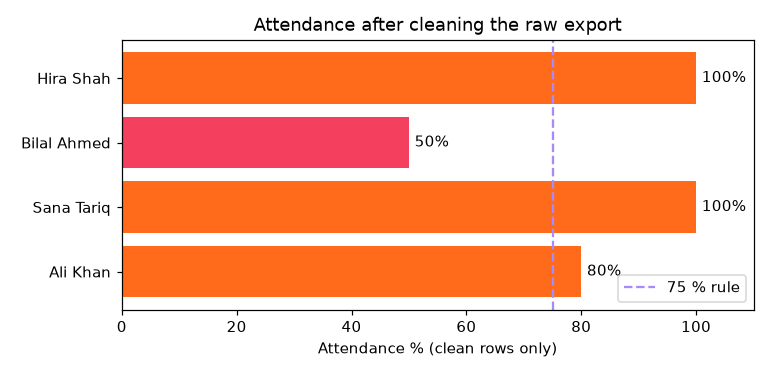

In [6]:
from IPython.display import Image, display
display(Image(filename='session-05_problem_attendance_cleaner.png'))  # chart saved by the cell above

## Example: `session-05_project_expense_tracker.py`

In [7]:
"""
Session 5 · Mini project: a persistent expense tracker (JSON file + exceptions)
------------------------------------------------------------------------------
Expenses are saved to expenses.json so they survive between runs. The program
  - loads the file safely (missing file -> start empty; corrupt file -> back it up),
  - validates every new expense with custom exceptions,
  - saves atomically (write to a temp file, then replace) so a crash never
    leaves a half-written file,
  - exports a CSV report and a chart by category.
Run:  python session-05_project_expense_tracker.py
"""
import csv
import json
import os
from datetime import date

DATA_FILE = "expenses.json"
CATEGORIES = {"food", "transport", "bills", "education", "other"}

class ExpenseError(Exception):
    """Base class for all tracker errors."""
class InvalidAmountError(ExpenseError):
    pass
class UnknownCategoryError(ExpenseError):
    pass

def load(path=DATA_FILE):
    """Return the list of expenses; never crash on a missing or broken file."""
    try:
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    except FileNotFoundError:
        print(f"  (no {path} yet - starting a new tracker)")
        return []
    except json.JSONDecodeError:
        os.replace(path, path + ".corrupt")
        print(f"  ({path} was corrupt - moved to {path}.corrupt, starting fresh)")
        return []

def save(expenses, path=DATA_FILE):
    """Atomic save: write a temporary file first, then swap it in."""
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(expenses, f, indent=2)
    os.replace(tmp, path)

def add(expenses, day, category, amount, note=""):
    """Validate and append one expense; raise an ExpenseError subclass on bad input."""
    try:
        amount = float(amount)
    except (TypeError, ValueError):
        raise InvalidAmountError(f"amount {amount!r} is not a number") from None
    if amount <= 0:
        raise InvalidAmountError("amount must be positive")
    category = category.lower().strip()
    if category not in CATEGORIES:
        raise UnknownCategoryError(f"{category!r} is not one of {sorted(CATEGORIES)}")
    date.fromisoformat(day)                      # raises ValueError for a bad date
    expenses.append({"date": day, "category": category, "amount": amount, "note": note})

# Start clean for a reproducible demo
for leftover in (DATA_FILE, DATA_FILE + ".corrupt"):
    if os.path.exists(leftover):
        os.remove(leftover)

print("Run 1: first use")
expenses = load()
entries = [
    ("2026-10-01", "Bills", 6_800, "electricity"), ("2026-10-02", "food", 1_250, "groceries"),
    ("2026-10-03", "transport", 900, "ride to campus"), ("2026-10-04", "education", "3,500", "books"),
    ("2026-10-05", "food", -40, "refund?"), ("2026-10-06", "shopping", 2_000, "shoes"),
    ("2026-10-07", "education", 3_500, "books"), ("2026-10-08", "food", 2_100, "dinner out"),
    ("2026-10-31", "transport", 1_400, "fuel"), ("2026-10-32", "other", 500, "typo date"),
]
for day, cat, amt, note in entries:
    try:
        add(expenses, day, cat, amt, note)
        print(f"  added   {day} {cat:<10} {float(amt):>8,.0f}")
    except ExpenseError as e:
        print(f"  skipped {day}: {type(e).__name__}: {e}")
    except ValueError as e:
        print(f"  skipped {day}: bad date ({e})")
save(expenses)
print(f"  saved {len(expenses)} expenses to {DATA_FILE}")

print("\nRun 2: the program starts again and reloads the file")
expenses = load()
print(f"  loaded {len(expenses)} expenses, total Rs {sum(e['amount'] for e in expenses):,.0f}")

print("\nRun 3: someone corrupts the file by hand")
with open(DATA_FILE, "a", encoding="utf-8") as f:
    f.write("}}} oops")
expenses_after = load()
print("  recovered list length:", len(expenses_after))

# Report from the good data loaded in run 2
totals = {}
for e in expenses:
    totals[e["category"]] = totals.get(e["category"], 0) + e["amount"]
with open("expense_report.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["category", "total", "share"])
    grand = sum(totals.values())
    for cat, t in sorted(totals.items(), key=lambda kv: -kv[1]):
        w.writerow([cat, f"{t:.0f}", f"{t / grand:.1%}"])
print("\nexpense_report.csv")
print(open("expense_report.csv", encoding="utf-8").read().rstrip())

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
cats = sorted(totals, key=totals.get, reverse=True)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(cats, [totals[c] for c in cats], color=["#FF6B1A", "#FCD34D", "#A78BFA", "#F43F5E"][:len(cats)])
ax.set_ylabel("Rs"); ax.set_title("October spending by category (valid entries only)")
fig.tight_layout(); fig.savefig("session-05_project_expense_tracker.png", dpi=110)

for f in (DATA_FILE, DATA_FILE + ".corrupt"):      # tidy the demo files, keep the report
    if os.path.exists(f):
        os.remove(f)
print("Chart saved: session-05_project_expense_tracker.png")

Run 1: first use
  (no expenses.json yet - starting a new tracker)
  added   2026-10-01 Bills         6,800
  added   2026-10-02 food          1,250
  added   2026-10-03 transport       900
  skipped 2026-10-04: InvalidAmountError: amount '3,500' is not a number
  skipped 2026-10-05: InvalidAmountError: amount must be positive
  skipped 2026-10-06: UnknownCategoryError: 'shopping' is not one of ['bills', 'education', 'food', 'other', 'transport']
  added   2026-10-07 education     3,500
  added   2026-10-08 food          2,100
  added   2026-10-31 transport     1,400
  skipped 2026-10-32: bad date (day is out of range for month)
  saved 6 expenses to expenses.json

Run 2: the program starts again and reloads the file
  loaded 6 expenses, total Rs 15,950

Run 3: someone corrupts the file by hand
  (expenses.json was corrupt - moved to expenses.json.corrupt, starting fresh)
  recovered list length: 0

expense_report.csv
category,total,share
bills,6800,42.6%
education,3500,21.9%
food,3350

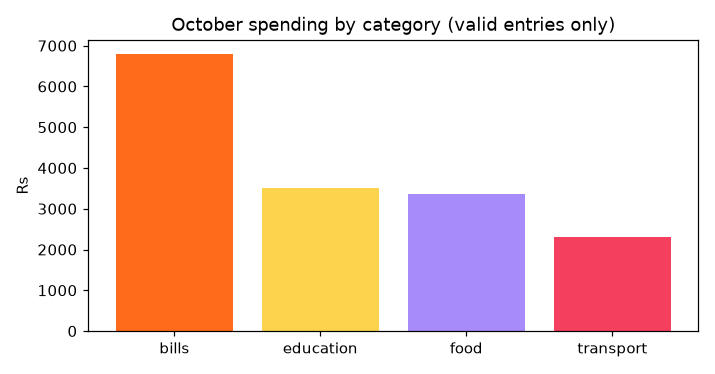

In [8]:
from IPython.display import Image, display
display(Image(filename='session-05_project_expense_tracker.png'))  # chart saved by the cell above